# **Assignment 5 : RNN vs LSTM vs GRU**

In [1]:
from google.colab import files
import pandas as pd
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Saving archive (9).zip to archive (9).zip
Dataset loaded successfully!
Dataset shape: (49396, 2)


,review,sentiment
0,"$25,000 Pyramid Clues: Deep Blue Sea. Tremors....",negative
1,0.5/10. This movie has absolutely nothing good...,negative
2,"0*'s Christian Slater, Tara Reid, Stephen Dorf...",negative
3,"102 Dalmatians (2000, Dir. Kevin Lima) <br /><...",negative
4,102 DALMATIANS [Walt Disney]: I wasn't a fan o...,negative


1. Dataset Preprocessing

In [2]:
print("Missing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
df['sentiment'] = df['sentiment'].map({
    'positive': 1,
    'negative': 0
})
X = df['review']
y = df['sentiment']
print("\nAfter preprocessing:")
print("Number of reviews:", len(X))
print("Positive reviews:", sum(y == 1))
print("Negative reviews:", sum(y == 0))
print("\nSample review:")
print(X.iloc[0])
print("Label:", y.iloc[0])

Missing values:
review       0
sentiment    0
dtype: int64

Duplicate rows: 0

After preprocessing:
Number of reviews: 49396
Positive reviews: 24698
Negative reviews: 24698

Sample review:
$25,000 Pyramid Clues: Deep Blue Sea. Tremors. Slither. Eight Legged Freaks.<br /><br />Pyramid Category: Movies that were funnier and more thrilling than Snakes on a Plane.<br /><br />Hell, with that definition I'd have to include the relatively harrowing journey of Ted and Elaine in Airplane! as superior to Snakes in both laughs and thrills.<br /><br />The sad truth is that this isn't even close to the mother of all unintentionally intentional funny snake movies: Anaconda! Besides the never to be seen again casting of JLo-Cube-O.Wilson-Stoltz-Wuhrer in the same flick, you had Jon Voight pulling off the all-time cinematic heist. His final scene alone represents everything SOAP tried and failed to do as a "so-ludicrous-it's-fun" movie.<br /><br />In the end, Snakes on a Plane is definitive proof that

2. Train-Test Split and Tokenization

In [3]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
MAX_WORDS = 10000
MAX_LEN = 200
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)
tokenizer.fit_on_texts(X_train)
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)
X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)
print("\nVocabulary size:", len(tokenizer.word_index))
print("Training data shape:", X_train_pad.shape)
print("Testing data shape:", X_test_pad.shape)

Training samples: 39516
Testing samples: 9880

Vocabulary size: 112168
Training data shape: (39516, 200)
Testing data shape: (9880, 200)


3. RNN Model

In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
rnn_model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=128, input_length=MAX_LEN),
    SimpleRNN(64),
    Dense(1, activation='sigmoid')
])
rnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
rnn_model.summary()
rnn_history = rnn_model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 42s 152ms/step - accuracy: 0.5002 - loss: 0.6954 - val_accuracy: 0.5016 - val_loss: 0.6944
Epoch 2/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 59s 238ms/step - accuracy: 0.6030 - loss: 0.6437 - val_accuracy: 0.5063 - val_loss: 0.7384
Epoch 3/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 60s 148ms/step - accuracy: 0.6923 - loss: 0.4951 - val_accuracy: 0.5090 - val_loss: 0.8362
Epoch 4/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 53s 198ms/step - accuracy: 0.7466 - loss: 0.3878 - val_accuracy: 0.5029 - val_loss: 0.9812
Epoch 5/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 92s 240ms/step - accuracy: 0.7623 - loss: 0.3608 - val_accuracy: 0.5102 - val_loss: 1.0282


4. RNN Model Evaluation

309/309 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step
===== RNN Evaluation =====
Accuracy  : 0.5152
Precision : 0.5129
Recall    : 0.6043
F1-Score  : 0.5548

Classification Report:
              precision    recall  f1-score   support

    Negative       0.52      0.43      0.47      4940
    Positive       0.51      0.60      0.55      4940

    accuracy                           0.52      9880
   macro avg       0.52      0.52      0.51      9880
weighted avg       0.52      0.52      0.51      9880



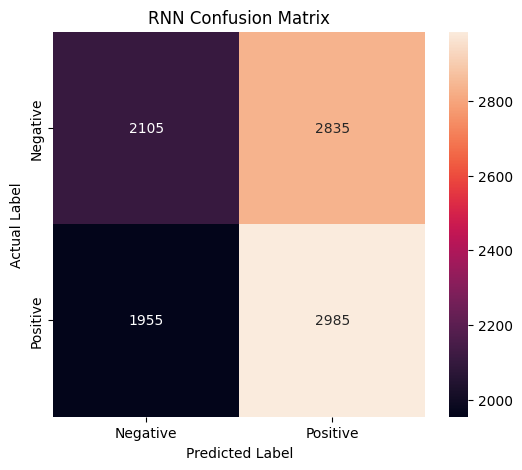

In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
y_pred_prob = rnn_model.predict(X_test_pad)
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()
rnn_accuracy = accuracy_score(y_test, y_pred)
rnn_precision = precision_score(y_test, y_pred)
rnn_recall = recall_score(y_test, y_pred)
rnn_f1 = f1_score(y_test, y_pred)
print("===== RNN Evaluation =====")
print(f"Accuracy  : {rnn_accuracy:.4f}")
print(f"Precision : {rnn_precision:.4f}")
print(f"Recall    : {rnn_recall:.4f}")
print(f"F1-Score  : {rnn_f1:.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("RNN Confusion Matrix")
plt.show()

5. LSTM Model

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
lstm_model = Sequential([
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=128,
        input_length=MAX_LEN
    ),
    LSTM(64),
    Dense(1, activation='sigmoid')
])
lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
lstm_model.summary()
lstm_history = lstm_model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 201s 792ms/step - accuracy: 0.5968 - loss: 0.6678 - val_accuracy: 0.6452 - val_loss: 0.6451
Epoch 2/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 119s 480ms/step - accuracy: 0.6308 - loss: 0.6427 - val_accuracy: 0.5768 - val_loss: 0.6690
Epoch 3/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 110s 444ms/step - accuracy: 0.6530 - loss: 0.6297 - val_accuracy: 0.6159 - val_loss: 0.6532
Epoch 4/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 111s 451ms/step - accuracy: 0.7754 - loss: 0.4905 - val_accuracy: 0.8446 - val_loss: 0.3824
Epoch 5/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 115s 464ms/step - accuracy: 0.8768 - loss: 0.3133 - val_accuracy: 0.8541 - val_loss: 0.3736


6. LSTM Model Evaluation

309/309 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step
===== LSTM Evaluation =====
Accuracy  : 0.8541
Precision : 0.8929
Recall    : 0.8049
F1-Score  : 0.8466

Classification Report:
              precision    recall  f1-score   support

    Negative       0.82      0.90      0.86      4940
    Positive       0.89      0.80      0.85      4940

    accuracy                           0.85      9880
   macro avg       0.86      0.85      0.85      9880
weighted avg       0.86      0.85      0.85      9880



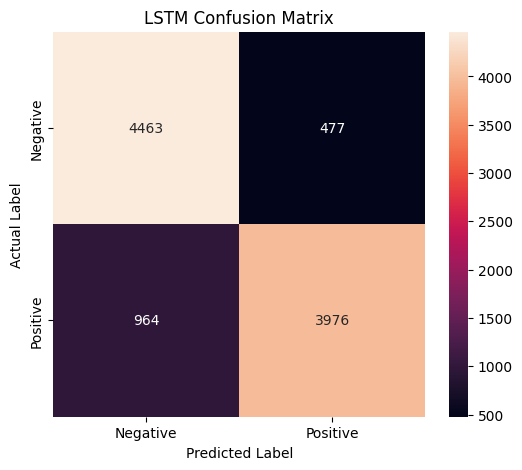

In [8]:
y_pred_prob_lstm = lstm_model.predict(X_test_pad)
y_pred_lstm = (y_pred_prob_lstm >= 0.5).astype(int).flatten()
lstm_accuracy = accuracy_score(y_test, y_pred_lstm)
lstm_precision = precision_score(y_test, y_pred_lstm)
lstm_recall = recall_score(y_test, y_pred_lstm)
lstm_f1 = f1_score(y_test, y_pred_lstm)
print("===== LSTM Evaluation =====")
print(f"Accuracy  : {lstm_accuracy:.4f}")
print(f"Precision : {lstm_precision:.4f}")
print(f"Recall    : {lstm_recall:.4f}")
print(f"F1-Score  : {lstm_f1:.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lstm,
    target_names=["Negative", "Positive"]
))
cm_lstm = confusion_matrix(y_test, y_pred_lstm)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_lstm,
    annot=True,
    fmt='d',
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("LSTM Confusion Matrix")
plt.show()

7. GRU Model

In [9]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense

gru_model = Sequential([
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=128,
        input_length=MAX_LEN
    ),
    GRU(64),
    Dense(1, activation='sigmoid')
])

gru_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

gru_model.summary()

gru_history = gru_model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 125s 496ms/step - accuracy: 0.5419 - loss: 0.6849 - val_accuracy: 0.7382 - val_loss: 0.6963
Epoch 2/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 137s 556ms/step - accuracy: 0.7469 - loss: 0.5245 - val_accuracy: 0.8421 - val_loss: 0.3856
Epoch 3/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 219s 867ms/step - accuracy: 0.8810 - loss: 0.2988 - val_accuracy: 0.8625 - val_loss: 0.3270
Epoch 4/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 129s 522ms/step - accuracy: 0.9257 - loss: 0.2071 - val_accuracy: 0.8732 - val_loss: 0.3055
Epoch 5/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 200s 812ms/step - accuracy: 0.9494 - loss: 0.1504 - val_accuracy: 0.8718 - val_loss: 0.3334


8. GRU Model Evaluation

309/309 ━━━━━━━━━━━━━━━━━━━━ 13s 40ms/step
===== GRU Evaluation =====
Accuracy  : 0.8686
Precision : 0.8602
Recall    : 0.8804
F1-Score  : 0.8701

Classification Report:
              precision    recall  f1-score   support

    Negative       0.88      0.86      0.87      4940
    Positive       0.86      0.88      0.87      4940

    accuracy                           0.87      9880
   macro avg       0.87      0.87      0.87      9880
weighted avg       0.87      0.87      0.87      9880



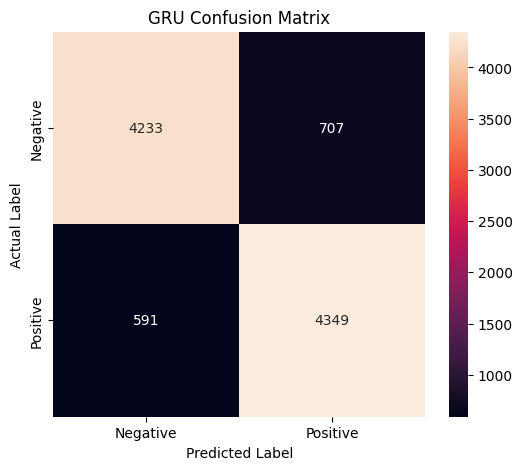

In [10]:
y_pred_prob_gru = gru_model.predict(X_test_pad)

y_pred_gru = (y_pred_prob_gru >= 0.5).astype(int).flatten()

gru_accuracy = accuracy_score(y_test, y_pred_gru)
gru_precision = precision_score(y_test, y_pred_gru)
gru_recall = recall_score(y_test, y_pred_gru)
gru_f1 = f1_score(y_test, y_pred_gru)

print("===== GRU Evaluation =====")
print(f"Accuracy  : {gru_accuracy:.4f}")
print(f"Precision : {gru_precision:.4f}")
print(f"Recall    : {gru_recall:.4f}")
print(f"F1-Score  : {gru_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_gru,
    target_names=["Negative", "Positive"]
))

cm_gru = confusion_matrix(y_test, y_pred_gru)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_gru,
    annot=True,
    fmt='d',
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("GRU Confusion Matrix")
plt.show()

9. Model Performance Comparison

===== Model Performance Comparison =====


,Model,Accuracy,Precision,Recall,F1-Score
0,RNN,0.5152,0.5129,0.6043,0.5548
1,LSTM,0.8541,0.8929,0.8049,0.8466
2,GRU,0.8686,0.8602,0.8804,0.8701


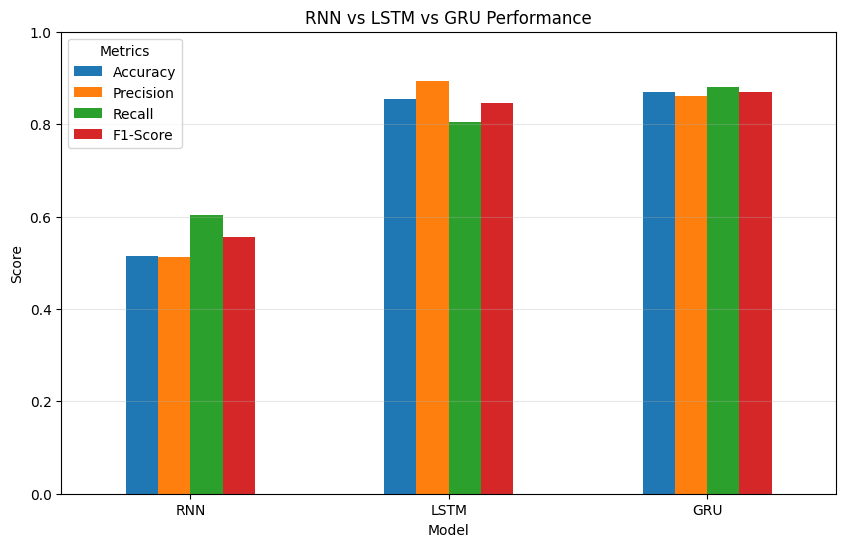

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
results = pd.DataFrame({
    'Model': ['RNN', 'LSTM', 'GRU'],
    'Accuracy': [0.5152, 0.8541, 0.8686],
    'Precision': [0.5129, 0.8929, 0.8602],
    'Recall': [0.6043, 0.8049, 0.8804],
    'F1-Score': [0.5548, 0.8466, 0.8701]
})

print("===== Model Performance Comparison =====")
display(results.round(4))

results_plot = results.set_index('Model')

results_plot.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("RNN vs LSTM vs GRU Performance")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis='y', alpha=0.3)

plt.show()

10. Training & Validation Performance

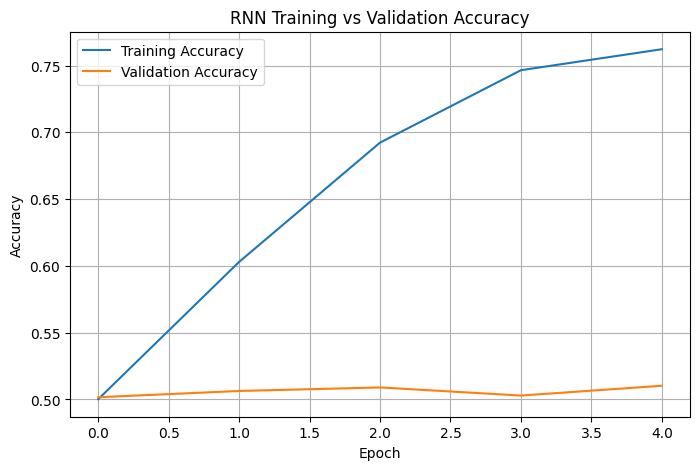

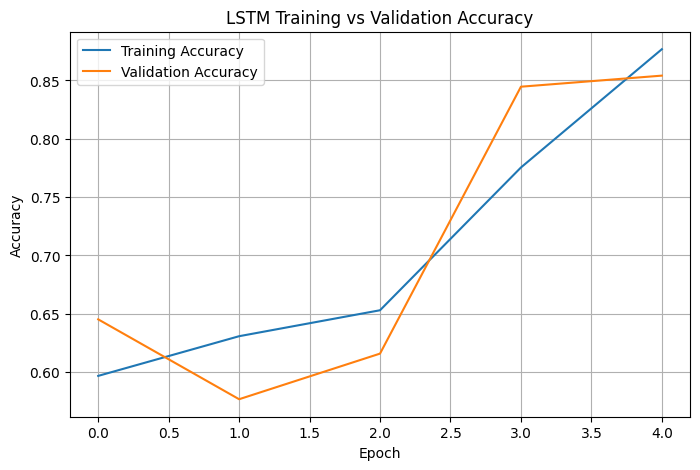

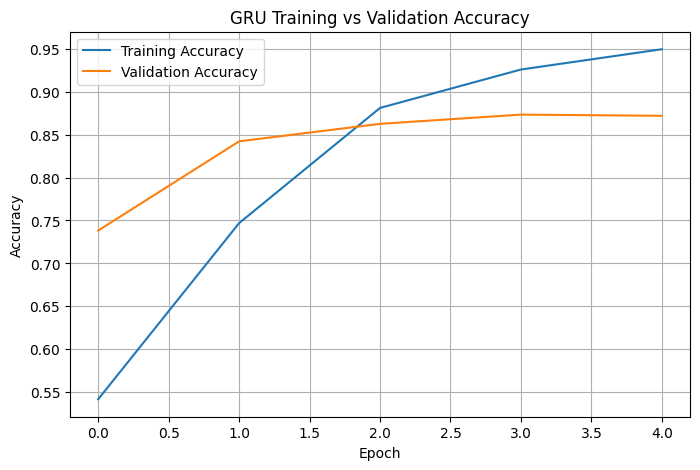

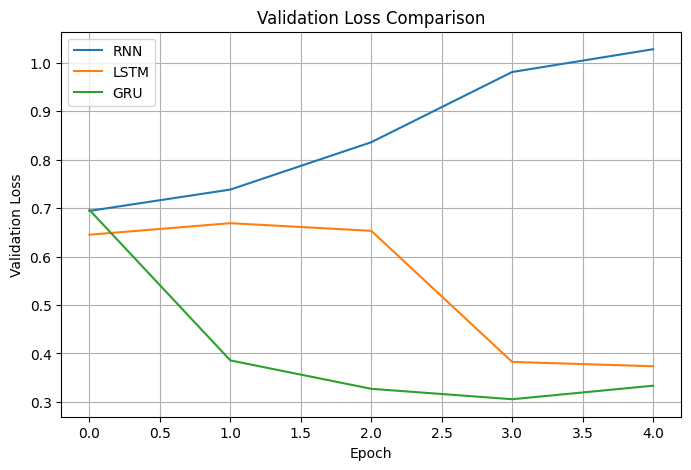

In [13]:
import matplotlib.pyplot as plt
# 1. RNN Accuracy
plt.figure(figsize=(8, 5))
plt.plot(rnn_history.history['accuracy'], label='Training Accuracy')
plt.plot(rnn_history.history['val_accuracy'], label='Validation Accuracy')

plt.title('RNN Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# 2. LSTM Accuracy
plt.figure(figsize=(8, 5))
plt.plot(lstm_history.history['accuracy'], label='Training Accuracy')
plt.plot(lstm_history.history['val_accuracy'], label='Validation Accuracy')

plt.title('LSTM Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# 3. GRU Accuracy
plt.figure(figsize=(8, 5))
plt.plot(gru_history.history['accuracy'], label='Training Accuracy')
plt.plot(gru_history.history['val_accuracy'], label='Validation Accuracy')

plt.title('GRU Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# 4. Validation Loss Comparison
plt.figure(figsize=(8, 5))
plt.plot(
    rnn_history.history['val_loss'],
    label='RNN'
)
plt.plot(
    lstm_history.history['val_loss'],
    label='LSTM'
)
plt.plot(
    gru_history.history['val_loss'],
    label='GRU'
)
plt.title('Validation Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True)
plt.show()